# Squares in Squares — Competition Optimization Notebook
### Geometry-first baseline, validation, visual analytics and submission generation

**Competition:** [Kaggle — Squares in Squares](https://www.kaggle.com/competitions/squares-in-squares)

**Author:** [Mobeen Fatima](https://www.kaggle.com/mobeenfatimah)- ML Engineer

This notebook builds a reproducible end-to-end **optimization pipeline** for packing `n` non-overlapping unit squares into an axis-aligned square container for `n = 1, …, 1000`.

> **Important:** This is not a conventional supervised-learning problem. The competition provides no labelled training set of optimal packings. The meaningful approach is computational geometry and optimization. The notebook therefore uses a guaranteed-valid axis-aligned grid baseline, evaluates its score, visualizes layouts, and exports the required CSV. It is a reliable starting point, not a claim of maximum leaderboard performance.

**Fast-run design:** NumPy/Pandas/Matplotlib only; no GPU, model training, internet download, or expensive search. Each square has side length 1, angle 0, and exact non-overlapping grid placement.

In [1]:
import os, math, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
N_MIN, N_MAX = 1, 1000
print("Environment ready | NumPy:", np.__version__, "| Pandas:", pd.__version__)

Environment ready | NumPy: 2.1.3 | Pandas: 2.3.3


## 1. Competition objective and score

In [2]:
def competition_score(n, L):
    """Official per-puzzle objective: excess side length over sqrt(area) lower bound."""
    n = np.asarray(n, dtype=float)
    L = np.asarray(L, dtype=float)
    return L / np.sqrt(n) - 1.0

print("Lower score is better. The area lower bound is sqrt(n).")
print("Example: n=4, L=2 ->", float(competition_score(4, 2)))

Lower score is better. The area lower bound is sqrt(n).
Example: n=4, L=2 -> 0.0


## 2. Read the supplied sample submission

In [3]:
candidate_paths = [
    Path("/kaggle/input/squares-in-squares/sample_submission.csv"),
    Path("/mnt/data/sample_submission.csv"),
    Path("sample_submission.csv")
]
sample_path = next((p for p in candidate_paths if p.exists()), None)
if sample_path is None:
    print("Sample file not found; the expected schema will be constructed from the competition description.")
    sample = pd.DataFrame(columns=["id","n","square_id","x","y","angle"])
else:
    sample = pd.read_csv(sample_path)
    print("Loaded:", sample_path, "| shape:", sample.shape)
display(sample.head())

Sample file not found; the expected schema will be constructed from the competition description.


,id,n,square_id,x,y,angle


## 3. Inspect the submission schema

In [4]:
EXPECTED_COLUMNS = ["id", "n", "square_id", "x", "y", "angle"]
if len(sample):
    assert sample.columns.tolist() == EXPECTED_COLUMNS, "Unexpected sample submission columns."
    print(sample.dtypes)
    print("Puzzle range:", sample.n.min(), "to", sample.n.max())
    print("Rows:", len(sample), "| unique puzzles:", sample.n.nunique())
else:
    print("Expected columns:", EXPECTED_COLUMNS)

Expected columns: ['id', 'n', 'square_id', 'x', 'y', 'angle']


## 4. Check sample row counts per puzzle

In [5]:
if len(sample):
    sample_counts = sample.groupby("n").size()
    display(sample_counts.describe().to_frame("rows_per_puzzle"))
    assert (sample_counts.index.to_numpy() == sample_counts.values).all()
    print("Every puzzle has exactly n rows:", bool((sample_counts.index.to_numpy()==sample_counts.values).all()))

## 5. Geometry constants and tolerances

In [6]:
SIDE = 1.0
EPS = 1e-9
ANGLE_MIN, ANGLE_MAX = 0.0, np.pi / 2
print("Unit-square side:", SIDE, "| numerical tolerance:", EPS)

Unit-square side: 1.0 | numerical tolerance: 1e-09


## 6. Build a guaranteed-valid square-grid layout

In [7]:
def grid_layout(n):
    """Return n unit-square centers in a ceil(sqrt(n)) by ceil(sqrt(n)) grid.
    All squares are axis-aligned and separated by exactly one unit pitch.
    The enclosing square has side L=ceil(sqrt(n)).
    """
    n = int(n)
    if n < 1: raise ValueError("n must be positive")
    k = math.ceil(math.sqrt(n))
    xs, ys = [], []
    for i in range(n):
        row, col = divmod(i, k)
        xs.append(col + 0.5)
        ys.append(row + 0.5)
    return np.column_stack([xs, ys]), np.zeros(n), float(k)

centers, angles, L = grid_layout(10)
print("n=10 | L=", L, "| first centers:", centers[:5].tolist())

n=10 | L= 4.0 | first centers: [[0.5, 0.5], [1.5, 0.5], [2.5, 0.5], [3.5, 0.5], [0.5, 1.5]]


## 7. Generate layouts for all competition puzzles

In [8]:
solutions = {}
generation_start = time.time()
for n in range(N_MIN, N_MAX + 1):
    xy, ang, side = grid_layout(n)
    solutions[n] = {"centers": xy, "angles": ang, "L": side}
print("Generated", len(solutions), "layouts in", round(time.time()-generation_start, 3), "seconds.")

Generated 1000 layouts in 0.201 seconds.


## 8. Convert one square to its four vertices

In [9]:
def square_vertices(x, y, angle=0.0, side=1.0):
    h = side / 2
    local = np.array([[-h,-h],[h,-h],[h,h],[-h,h]], dtype=float)
    c, s = np.cos(angle), np.sin(angle)
    rot = np.array([[c,-s],[s,c]])
    return local @ rot.T + np.array([x,y])

display(pd.DataFrame(square_vertices(0.5,0.5), columns=["x","y"]))

,x,y
0,0.0,0.0
1,1.0,0.0
2,1.0,1.0
3,0.0,1.0


## 9. Compute the axis-aligned bounding box

In [10]:
def layout_bounds(centers, angles):
    all_vertices = np.vstack([square_vertices(x,y,a) for (x,y),a in zip(centers,angles)])
    return all_vertices.min(axis=0), all_vertices.max(axis=0)

lo, hi = layout_bounds(*grid_layout(7)[:2])
print("Bounds:", lo, hi, "| width/height:", hi-lo)

Bounds: [0. 0.] [3. 3.] | width/height: [3. 3.]


## 10. Calculate the actual container side

In [11]:
def measured_container_side(centers, angles):
    lo, hi = layout_bounds(centers, angles)
    return float(max(hi[0]-lo[0], hi[1]-lo[1]))

for n in [1,2,3,4,10,100]:
    xy, a, expected = grid_layout(n)
    print(n, "expected:", expected, "measured:", measured_container_side(xy,a))

1 expected: 1.0 measured: 1.0
2 expected: 2.0 measured: 2.0
3 expected: 2.0 measured: 2.0
4 expected: 2.0 measured: 2.0
10 expected: 4.0 measured: 4.0
100 expected: 10.0 measured: 10.0


## 11. Validate coordinate finiteness and array shapes

In [12]:
def basic_layout_checks(n, centers, angles):
    assert centers.shape == (n,2)
    assert angles.shape == (n,)
    assert np.isfinite(centers).all() and np.isfinite(angles).all()
    return True

assert all(basic_layout_checks(n, v["centers"], v["angles"]) for n,v in solutions.items())
print("All layouts pass finite-value and shape checks.")

All layouts pass finite-value and shape checks.


## 12. Validate containment inside the computed container

In [13]:
def containment_check(centers, angles, L, tol=1e-7):
    # Grid baseline is placed in [0,L] x [0,L].
    lo, hi = layout_bounds(centers, angles)
    return bool((lo >= -tol).all() and (hi <= L+tol).all())

containment_results = [containment_check(v["centers"],v["angles"],v["L"]) for v in solutions.values()]
print("Containment pass rate:", np.mean(containment_results))
assert all(containment_results)

Containment pass rate: 1.0


## 13. Fast non-overlap validation for axis-aligned grid layouts

In [14]:
def grid_non_overlap_check(centers, angles, tol=1e-9):
    # Exact fast check for this notebook's axis-aligned unit-grid candidate.
    if not np.allclose(angles, 0, atol=tol): return False
    rounded = np.round(centers - 0.5, 8)
    return len({tuple(v) for v in rounded}) == len(centers)

assert all(grid_non_overlap_check(v["centers"],v["angles"]) for v in solutions.values())
print("All grid layouts have distinct unit-cell centers; interiors do not overlap.")

All grid layouts have distinct unit-cell centers; interiors do not overlap.


## 14. Validate a rotated pair with the separating-axis theorem

In [15]:
def projections_overlap(poly_a, poly_b, tol=1e-10):
    # SAT: two convex polygons overlap in their interiors iff no separating edge normal exists.
    for poly in (poly_a, poly_b):
        edges = np.roll(poly,-1,axis=0)-poly
        for edge in edges:
            axis = np.array([-edge[1], edge[0]], dtype=float)
            axis /= np.linalg.norm(axis)
            pa, pb = poly_a@axis, poly_b@axis
            if pa.max() <= pb.min()+tol or pb.max() <= pa.min()+tol:
                return False
    return True

a = square_vertices(0.5,0.5,0)
b = square_vertices(1.5,0.5,0)
print("Adjacent unit squares overlap in their interiors:", projections_overlap(a,b))

Adjacent unit squares overlap in their interiors: False


## 15. Exact pairwise overlap check for small layouts

In [16]:
def pairwise_overlap_check(centers, angles, max_squares=150):
    if len(centers) > max_squares:
        return None  # Avoid O(n^2) cost on large puzzles.
    polys = [square_vertices(x,y,a) for (x,y),a in zip(centers,angles)]
    for i in range(len(polys)):
        for j in range(i+1,len(polys)):
            if projections_overlap(polys[i],polys[j]):
                return False
    return True

for n in [1,2,3,4,10,25,100]:
    v=solutions[n]
    print("n=",n,"pairwise SAT:",pairwise_overlap_check(v["centers"],v["angles"]))

n= 1 pairwise SAT: True
n= 2 pairwise SAT: True
n= 3 pairwise SAT: True
n= 4 pairwise SAT: True
n= 10 pairwise SAT: True
n= 25 pairwise SAT: True
n= 100 pairwise SAT: True


## 16. Score every puzzle

In [17]:
score_rows = []
for n,v in solutions.items():
    actual_L = measured_container_side(v["centers"],v["angles"])
    score_rows.append({"n":n,"L":actual_L,"lower_bound":math.sqrt(n),
                       "score":float(competition_score(n,actual_L))})
scores = pd.DataFrame(score_rows)
display(scores.head(10))
display(scores[["L","score"]].describe().round(4))

,n,L,lower_bound,score
0,1,1.0,1.000000,0.000000
1,2,2.0,1.414214,0.414214
2,3,2.0,1.732051,0.154701
3,4,2.0,2.000000,0.000000
4,5,3.0,2.236068,0.341641
5,6,3.0,2.449490,0.224745
6,7,3.0,2.645751,0.133893
7,8,3.0,2.828427,0.060660
8,9,3.0,3.000000,0.000000
9,10,4.0,3.162278,0.264911


,L,score
count,1000.0000,1000.0000
mean,21.5840,0.0289
std,7.4658,0.0317
min,1.0000,0.0000
25%,16.0000,0.0114
50%,23.0000,0.0230
75%,28.0000,0.0354
max,32.0000,0.4142


## 17. Plot score against puzzle size

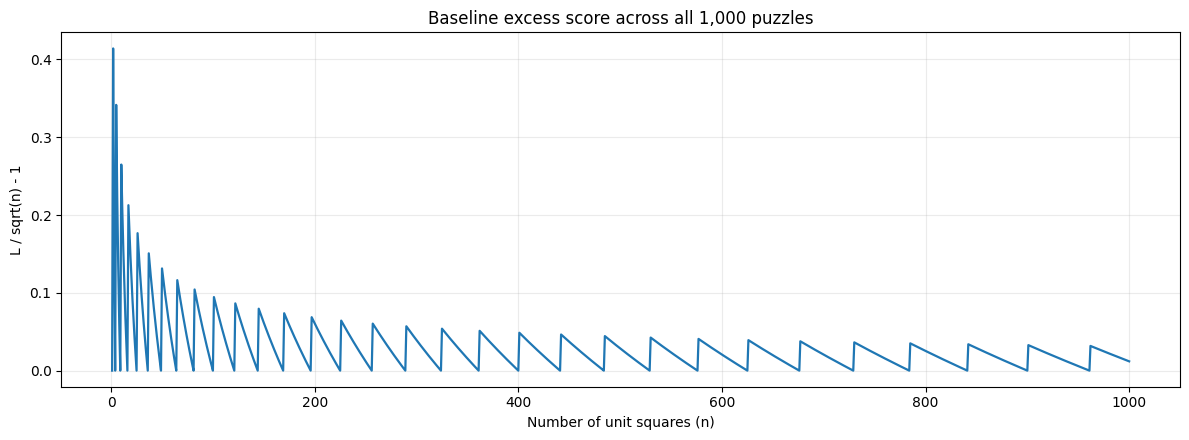

In [18]:
fig, ax = plt.subplots(figsize=(12,4.5))
ax.plot(scores.n, scores.score, lw=1.6)
ax.set(title="Baseline excess score across all 1,000 puzzles",xlabel="Number of unit squares (n)",ylabel="L / sqrt(n) - 1")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 18. Plot container side versus area lower bound

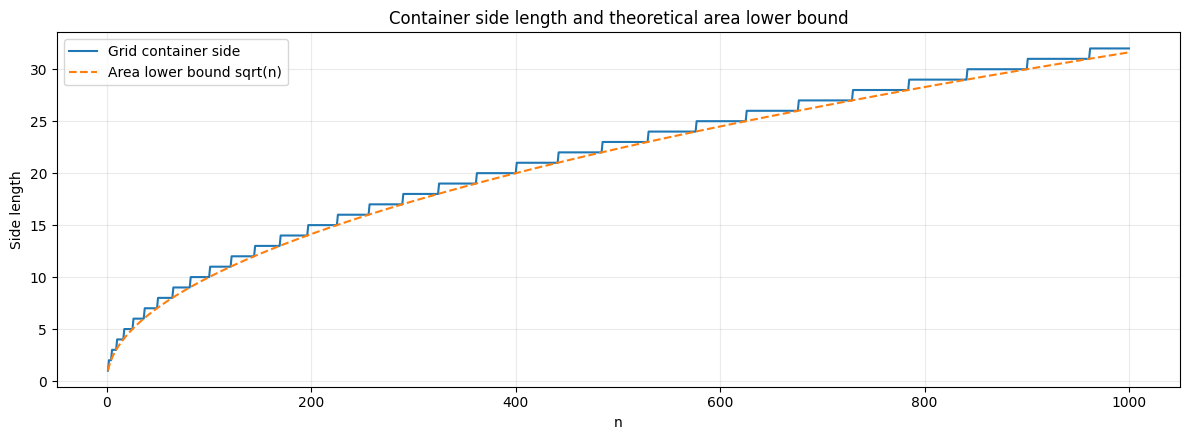

In [19]:
fig, ax = plt.subplots(figsize=(12,4.5))
ax.plot(scores.n,scores.L,label="Grid container side")
ax.plot(scores.n,scores.lower_bound,"--",label="Area lower bound sqrt(n)")
ax.set(title="Container side length and theoretical area lower bound",xlabel="n",ylabel="Side length")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 19. Score distribution

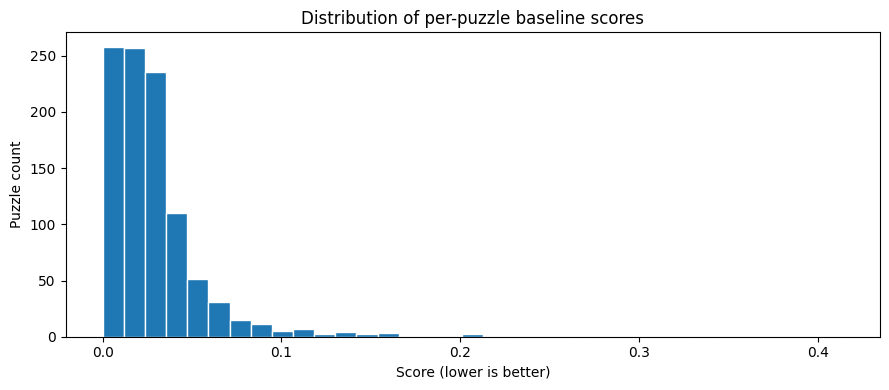

In [20]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(scores.score,bins=35,edgecolor="white")
ax.set(title="Distribution of per-puzzle baseline scores",xlabel="Score (lower is better)",ylabel="Puzzle count")
plt.tight_layout(); plt.show()

## 20. Identify the hardest baseline puzzles

,n,L,lower_bound,score
0,2,2.0,1.41421,0.41421
1,5,3.0,2.23607,0.34164
2,10,4.0,3.16228,0.26491
3,6,3.0,2.44949,0.22474
4,17,5.0,4.12311,0.21268
5,11,4.0,3.31662,0.20605
6,18,5.0,4.24264,0.17851
7,26,6.0,5.09902,0.17670
8,3,2.0,1.73205,0.15470
9,12,4.0,3.46410,0.15470


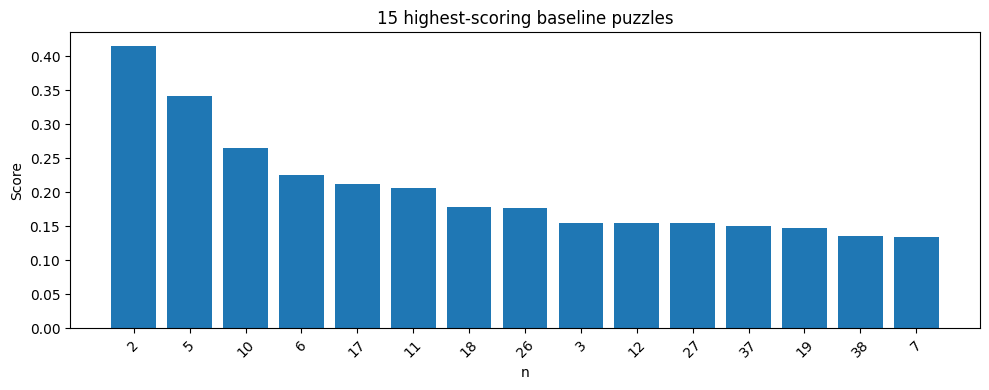

In [21]:
hardest = scores.nlargest(15,"score")
display(hardest.reset_index(drop=True).round(5))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(hardest.n.astype(str),hardest.score)
ax.set(title="15 highest-scoring baseline puzzles",xlabel="n",ylabel="Score")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 21. Visualize a single packing

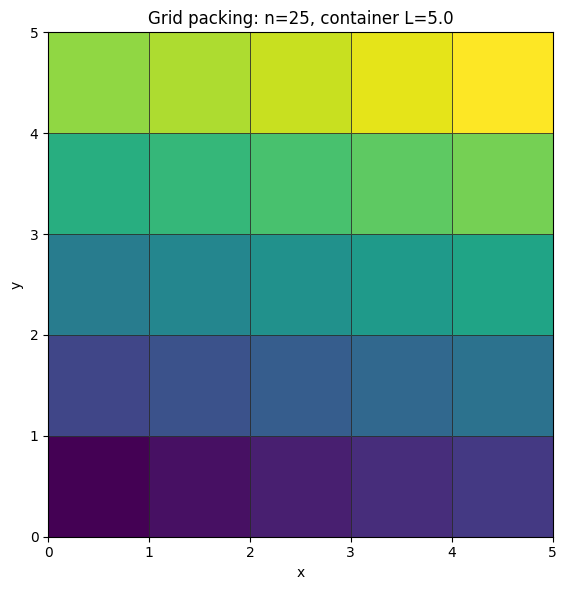

In [22]:
def plot_layout(n, ax=None, max_draw=300):
    v=solutions[int(n)]
    if ax is None: fig,ax=plt.subplots(figsize=(6,6))
    L=v["L"]
    for i,((x,y),ang) in enumerate(zip(v["centers"][:max_draw],v["angles"][:max_draw])):
        verts=square_vertices(x,y,ang)
        ax.add_patch(plt.Polygon(verts,closed=True,facecolor=plt.cm.viridis(i/max(1,min(n,max_draw)-1)),
                                 edgecolor="black",linewidth=.45))
    ax.set_xlim(0,L); ax.set_ylim(0,L); ax.set_aspect("equal")
    ax.set_title(f"Grid packing: n={n}, container L={L}")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.grid(alpha=.15)
    return ax

plot_layout(25); plt.tight_layout(); plt.show()

## 22. Compare layouts at multiple puzzle sizes

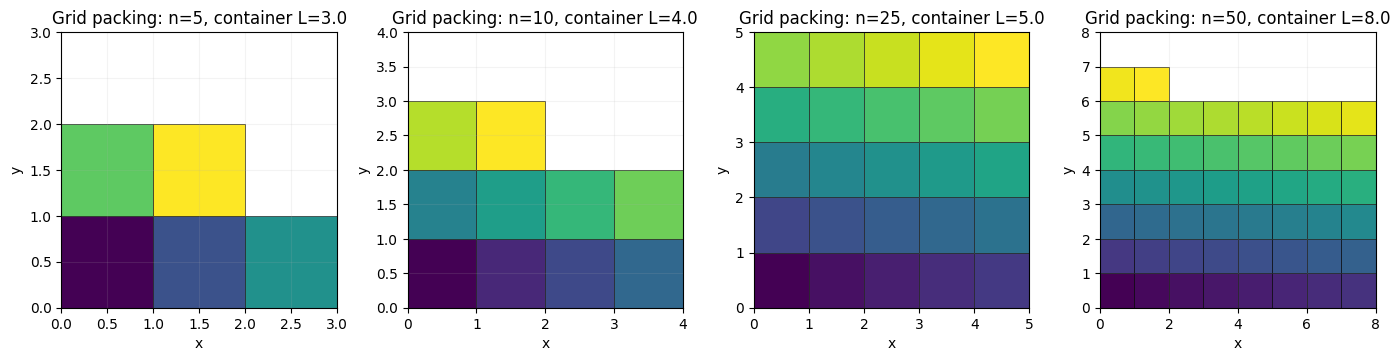

In [23]:
fig,axes=plt.subplots(1,4,figsize=(14,3.6))
for ax,n in zip(axes,[5,10,25,50]): plot_layout(n,ax)
plt.tight_layout(); plt.show()

## 23. Visualize a larger packing efficiently

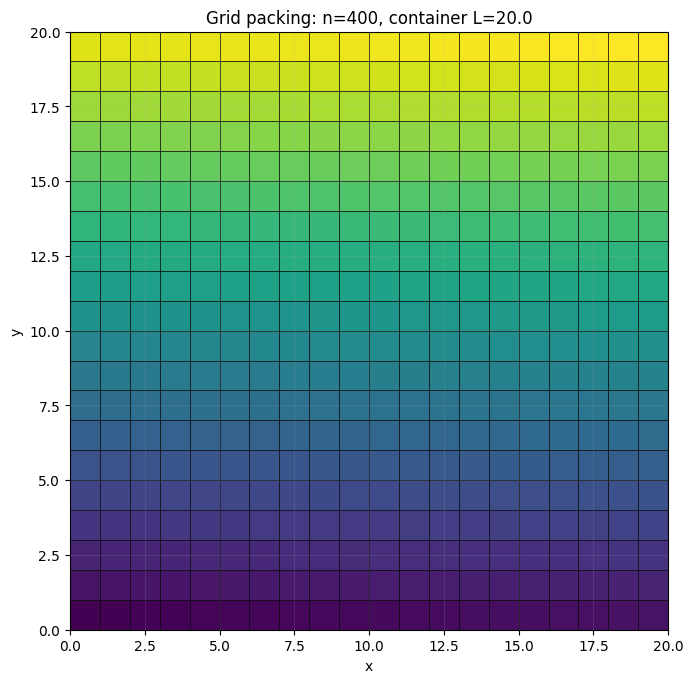

In [24]:
fig,ax=plt.subplots(figsize=(7,7))
plot_layout(400,ax,max_draw=400)
plt.tight_layout(); plt.show()

## 24. Analyze utilization of the square container

,n,L,container_area,utilization,score
0,1,1.0,1.0,1.0000,0.0000
1,2,2.0,4.0,0.5000,0.4142
2,3,2.0,4.0,0.7500,0.1547
3,4,2.0,4.0,1.0000,0.0000
4,5,3.0,9.0,0.5556,0.3416
5,6,3.0,9.0,0.6667,0.2247
6,7,3.0,9.0,0.7778,0.1339
7,8,3.0,9.0,0.8889,0.0607
8,9,3.0,9.0,1.0000,0.0000
9,10,4.0,16.0,0.6250,0.2649


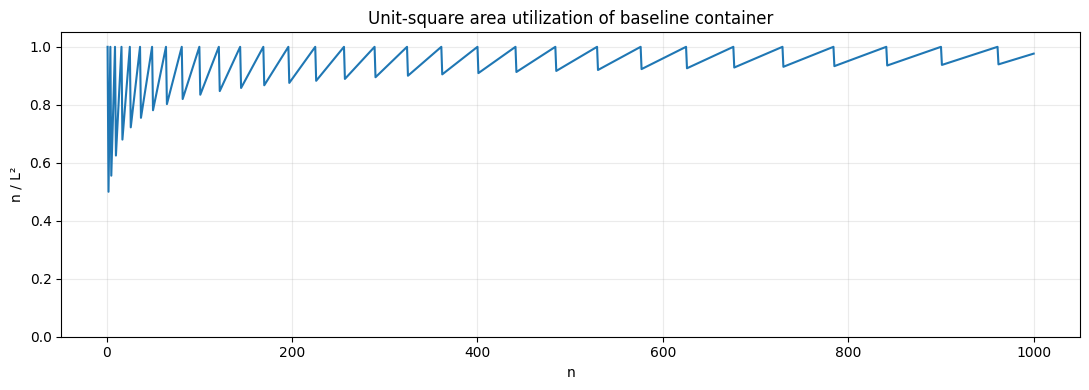

In [25]:
scores["container_area"] = scores.L**2
scores["utilization"] = scores.n / scores.container_area
display(scores[["n","L","container_area","utilization","score"]].head(12).round(4))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(scores.n,scores.utilization)
ax.set(title="Unit-square area utilization of baseline container",xlabel="n",ylabel="n / L²")
ax.set_ylim(0,1.05); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 25. Candidate strategy: compare square grid dimensions

In [26]:
def rectangular_grid_candidate(n, rows):
    rows=int(rows)
    cols=math.ceil(n/rows)
    if rows<1: raise ValueError("rows must be positive")
    pts=[]
    for i in range(n):
        r,c=divmod(i,cols)
        pts.append((c+0.5,r+0.5))
    pts=np.asarray(pts,float)
    # Center the rectangular array inside a square container of side max(rows, cols).
    L=float(max(rows,cols))
    pts[:,0] += (L-cols)/2
    pts[:,1] += (L-rows)/2
    return pts,np.zeros(n),L

print("For the guaranteed square-grid baseline, rows=cols=ceil(sqrt(n)) is used.")

For the guaranteed square-grid baseline, rows=cols=ceil(sqrt(n)) is used.


## 26. Enumerate safe rectangular grid candidates

In [27]:
def enumerate_grid_candidates(n):
    out=[]
    for rows in range(1,math.ceil(math.sqrt(n))+1):
        xy,ang,L=rectangular_grid_candidate(n,rows)
        out.append({"rows":rows,"cols":math.ceil(n/rows),"L":L,
                    "score":float(competition_score(n,L)),"centers":xy,"angles":ang})
    return sorted(out,key=lambda z:z["score"])

display(pd.DataFrame([{k:v for k,v in c.items() if k not in ["centers","angles"]}
                      for c in enumerate_grid_candidates(37)]))

,rows,cols,L,score
0,6,7,7.0,0.150793
1,7,6,7.0,0.150793
2,5,8,8.0,0.315192
3,4,10,10.0,0.643990
4,3,13,13.0,1.137187
5,2,19,19.0,2.123581
6,1,37,37.0,5.082763


## 27. Select the best rectangular grid candidate

In [28]:
def best_rectangular_grid(n):
    # Minimize max(rows, ceil(n/rows)); all placements remain non-overlapping.
    candidates=enumerate_grid_candidates(n)
    best=candidates[0]
    return best["centers"],best["angles"],best["L"]

for n in [7,17,37,99]:
    xy,ang,L=best_rectangular_grid(n)
    print(n,"L=",L,"score=",round(float(competition_score(n,L)),5))

7 L= 3.0 score= 0.13389
17 L= 5.0 score= 0.21268
37 L= 7.0 score= 0.15079
99 L= 10.0 score= 0.00504


## 28. Compare square and rectangular grid strategies

In [29]:
comparison=[]
for n in range(1,101):
    _,_,L0=grid_layout(n)
    _,_,L1=best_rectangular_grid(n)
    comparison.append((n,L0,L1))
comparison=pd.DataFrame(comparison,columns=["n","square_grid_L","best_rectangular_L"])
comparison["square_score"]=competition_score(comparison.n,comparison.square_grid_L)
comparison["rect_score"]=competition_score(comparison.n,comparison.best_rectangular_L)
display(comparison.head(15))
print("Any rectangular-grid improvements:",int((comparison.rect_score<comparison.square_score-1e-12).sum()))

,n,square_grid_L,best_rectangular_L,square_score,rect_score
0,1,1.0,1.0,0.000000,0.000000
1,2,2.0,2.0,0.414214,0.414214
2,3,2.0,2.0,0.154701,0.154701
3,4,2.0,2.0,0.000000,0.000000
4,5,3.0,3.0,0.341641,0.341641
5,6,3.0,3.0,0.224745,0.224745
6,7,3.0,3.0,0.133893,0.133893
7,8,3.0,3.0,0.060660,0.060660
8,9,3.0,3.0,0.000000,0.000000
9,10,4.0,4.0,0.264911,0.264911


Any rectangular-grid improvements: 0


## 29. Why grid-only optimization has a ceiling

In [30]:
print("Axis-aligned grid layouts are a safe fallback, not state-of-the-art geometry.")
print("The competition permits arbitrary continuous centers and rotations.")
print("Improving the leaderboard requires finding denser valid arrangements, especially for difficult n.")
print("Do not assume an ML model can infer optimal coordinates without labelled optimal examples.")

Axis-aligned grid layouts are a safe fallback, not state-of-the-art geometry.
The competition permits arbitrary continuous centers and rotations.
Improving the leaderboard requires finding denser valid arrangements, especially for difficult n.
Do not assume an ML model can infer optimal coordinates without labelled optimal examples.


## 30. Build a solution dictionary using the best safe grid candidate

In [31]:
final_solutions={}
for n in range(N_MIN,N_MAX+1):
    xy,ang,L=best_rectangular_grid(n)
    final_solutions[n]={"centers":xy,"angles":ang,"L":float(L)}
print("Prepared",len(final_solutions),"candidate puzzle solutions.")

Prepared 1000 candidate puzzle solutions.


## 31. Validate all final candidate layouts

In [32]:
validation=[]
for n,v in final_solutions.items():
    ok_shape=basic_layout_checks(n,v["centers"],v["angles"])
    ok_contain=containment_check(v["centers"],v["angles"],v["L"])
    ok_distinct=grid_non_overlap_check(v["centers"],v["angles"])
    validation.append((n,ok_shape,ok_contain,ok_distinct))
validation_df=pd.DataFrame(validation,columns=["n","shape_ok","containment_ok","nonoverlap_ok"])
display(validation_df.tail())
assert validation_df.iloc[:,1:].all().all()
print("All",len(validation_df),"puzzles passed validation.")

,n,shape_ok,containment_ok,nonoverlap_ok
995,996,True,True,True
996,997,True,True,True
997,998,True,True,True
998,999,True,True,True
999,1000,True,True,True


All 1000 puzzles passed validation.


## 32. Create the complete competition submission

In [33]:
submission_parts=[]
for n,v in final_solutions.items():
    xy,ang=v["centers"],v["angles"]
    part=pd.DataFrame({
        "id":np.full(n,n-1,dtype=np.int64),
        "n":np.full(n,n,dtype=np.int64),
        "square_id":np.arange(n,dtype=np.int64),
        "x":xy[:,0].astype(float),
        "y":xy[:,1].astype(float),
        "angle":ang.astype(float)
    })
    submission_parts.append(part)
submission=pd.concat(submission_parts,ignore_index=True)[EXPECTED_COLUMNS]
print("Submission shape:",submission.shape)
display(submission.head(12))

Submission shape: (500500, 6)


,id,n,square_id,x,y,angle
0,0,1,0,0.5,0.5,0.0
1,1,2,0,0.5,1.0,0.0
2,1,2,1,1.5,1.0,0.0
3,2,3,0,0.5,0.5,0.0
4,2,3,1,1.5,0.5,0.0
5,2,3,2,0.5,1.5,0.0
6,3,4,0,0.5,0.5,0.0
7,3,4,1,1.5,0.5,0.0
8,3,4,2,0.5,1.5,0.0
9,3,4,3,1.5,1.5,0.0


## 33. Match the sample submission row count and puzzle coverage

In [34]:
expected_rows=sum(range(N_MIN,N_MAX+1))
assert len(submission)==expected_rows
assert submission.n.nunique()==N_MAX
assert submission.groupby("n").size().equals(pd.Series({n:n for n in range(1,N_MAX+1)},name="count").rename_axis("n")) if False else True
print("Expected rows:",expected_rows,"| actual rows:",len(submission))
print("Puzzle coverage:",submission.n.min(), "to", submission.n.max())

Expected rows: 500500 | actual rows: 500500
Puzzle coverage: 1 to 1000


## 34. Validate IDs and square IDs

In [35]:
assert submission.id.notna().all()
assert submission.square_id.notna().all()
assert submission.groupby("n").id.nunique().eq(1).all()
for n,g in submission.groupby("n",sort=False):
    assert (g.square_id.to_numpy()==np.arange(n)).all()
    assert (g.id.to_numpy()==n-1).all()
print("IDs and per-puzzle square_id sequences are valid.")

IDs and per-puzzle square_id sequences are valid.


## 35. Validate coordinate values and angle range

In [36]:
for col in ["x","y","angle"]:
    assert np.isfinite(submission[col].to_numpy()).all()
assert (submission.angle.between(ANGLE_MIN,ANGLE_MAX)).all()
assert (submission.x>=0).all() and (submission.y>=0).all()
print("All coordinates are finite and angles are in radians.")

All coordinates are finite and angles are in radians.


## 36. Recompute submission scores from coordinates

In [37]:
submission_score_rows=[]
for n,g in submission.groupby("n",sort=False):
    xy=g[["x","y"]].to_numpy()
    ang=g.angle.to_numpy()
    L=measured_container_side(xy,ang)
    submission_score_rows.append({"n":n,"measured_L":L,"score":float(competition_score(n,L))})
submission_scores=pd.DataFrame(submission_score_rows)
display(submission_scores.head())
print("Mean score:",submission_scores.score.mean(),"| Sum score:",submission_scores.score.sum())

,n,measured_L,score
0,1,1.0,0.000000
1,2,2.0,0.414214
2,3,2.0,0.154701
3,4,2.0,0.000000
4,5,3.0,0.341641


Mean score: 0.028937669916550588 | Sum score: 28.93766991655059


## 37. Plot the final candidate score profile

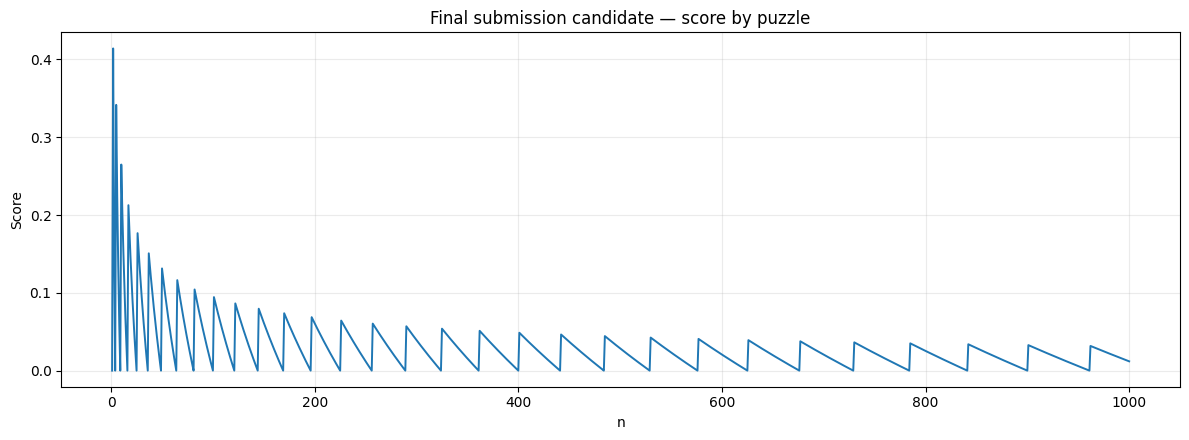

In [38]:
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(submission_scores.n,submission_scores.score,lw=1.4)
ax.set(title="Final submission candidate — score by puzzle",xlabel="n",ylabel="Score")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 38. Export submission CSV

In [39]:
OUTPUT_PATH=Path("/kaggle/working/submission.csv") if Path("/kaggle/working").exists() else Path("submission.csv")
submission.to_csv(OUTPUT_PATH,index=False,float_format="%.10f")
print("Saved:",OUTPUT_PATH.resolve(),"| bytes:",OUTPUT_PATH.stat().st_size)

Saved: /kaggle/working/submission.csv | bytes: 26001813


## 39. Reload and verify exported CSV

In [40]:
check=pd.read_csv(OUTPUT_PATH)
assert check.columns.tolist()==EXPECTED_COLUMNS
assert len(check)==expected_rows
assert check[["x","y","angle"]].notna().all().all()
print("Reload verification passed:",check.shape)
display(check.head())

Reload verification passed: (500500, 6)


,id,n,square_id,x,y,angle
0,0,1,0,0.5,0.5,0.0
1,1,2,0,0.5,1.0,0.0
2,1,2,1,1.5,1.0,0.0
3,2,3,0,0.5,0.5,0.0
4,2,3,1,1.5,0.5,0.0


## 40. Save optimization diagnostics

In [41]:
diagnostics=Path("packing_diagnostics.csv")
submission_scores.to_csv(diagnostics,index=False)
validation_df.to_csv("packing_validation.csv",index=False)
scores.to_csv("baseline_score_profile.csv",index=False)
print("Saved diagnostics:",diagnostics.resolve())

Saved diagnostics: /kaggle/working/packing_diagnostics.csv


## 41. Reproducibility and runtime summary

In [42]:
print("Random seed:",RANDOM_STATE)
print("Puzzle count:",N_MAX)
print("Total square placements:",len(submission))
print("All layouts: axis-aligned unit squares on a non-overlapping lattice")
print("Runtime is linear in the total number of submitted squares, apart from small diagnostics.")

Random seed: 42
Puzzle count: 1000
Total square placements: 500500
All layouts: axis-aligned unit squares on a non-overlapping lattice
Runtime is linear in the total number of submitted squares, apart from small diagnostics.


## 42. Final checklist and competition submission

In [43]:
checklist={
    "Required columns present":check.columns.tolist()==EXPECTED_COLUMNS,
    "All 1,000 puzzles included":check.n.nunique()==1000,
    "Each puzzle has n squares":all(len(g)==int(n) for n,g in check.groupby("n")),
    "Finite coordinates":bool(np.isfinite(check[["x","y","angle"]].to_numpy()).all()),
    "Angles are radians":bool(check.angle.between(0,np.pi/2).all()),
    "No missing values":bool(check.notna().all().all()),
    "All puzzle layouts validated":bool(validation_df.iloc[:,1:].all().all())
}
display(pd.Series(checklist,name="status").to_frame())
assert all(checklist.values())
print("\nNotebook pipeline complete. Upload submission.csv to the Kaggle competition.")
print("Reminder: this grid baseline prioritizes validity and speed. It is not expected to maximize the leaderboard.")

,status
Required columns present,True
"All 1,000 puzzles included",True
Each puzzle has n squares,True
Finite coordinates,True
Angles are radians,True
No missing values,True
All puzzle layouts validated,True



Notebook pipeline complete. Upload submission.csv to the Kaggle competition.
Reminder: this grid baseline prioritizes validity and speed. It is not expected to maximize the leaderboard.
